## 1) التجهيز وتحميل البيانات

In [1]:
import sys
from pathlib import Path

import pandas as pd

# add the project root to the import path (the notebook lives in notebooks/)
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

try:                                   # for Arabic plot labels
    import arabic_reshaper, bidi       # noqa: F401
except ImportError:
    !python -m pip install -q arabic-reshaper python-bidi

from common import Columns, DATA_DIR, RANDOM_STATE, load_data
from eda_tools import (ArabicPlotter, ArabicText, ClassDistribution, DuplicateFinder, LabelAuditor,
                       LeakageDetector, LengthProfile, PatternCounter, SimilarityFinder, SplitOverview,
                       WordFrequency)

pd.set_option("display.max_colwidth", 120)
pd.set_option("display.width", 200)
plotter = ArabicPlotter()
print("DATA_DIR =", DATA_DIR)

DATA_DIR = C:\nlp\arabic-medical-question-classification\data


In [2]:
train, val, test, label_map = load_data()
splits = {"train": train, "val": val, "test": test}
label_map

,category,label_id
0,أمراض العيون,0
1,الأمراض الجلدية,1
2,الطب العام,2
3,أمراض نسائية,3
4,أمراض الغدد الصماء,4
5,أمراض الأطفال,5
6,ارتفاع ضغط الدم,6
7,صحة الأسنان,7
8,أمراض الدم,8
9,أمراض الجهاز التنفسي,9


ملف الترميز فيه 10 فئات

## 2) الأساسيات: الحجم والأعمدة وعيّنة عشوائية

**المشكلة:** قبل أي تحليل لازم نتأكد إن الملفات كاملة وسليمة.
**الطريقة:** جدول ملخّص لكل ملف (صفوف، أعمدة، فراغات، ids فريدة) + فحص تقاطع الـ ids بين الملفات + عيّنة 30 سؤال نقراها بعيننا.

In [3]:
overview = SplitOverview(splits)
overview.summary()

,rows,columns,null_cells,empty_text,unique_ids,labels
split,,,,,,
train,58135,"id, question, category",0,0,58135,14.0
val,7267,"id, question, category",0,0,7267,14.0
test,7267,"id, question",0,0,7267,NaN


In [4]:
overview.id_overlap()

,shared_ids
pair,
train & val,0
train & test,0
val & test,0


In [5]:
train.dtypes.to_frame('dtype').T

,id,question,category
dtype,int64,object,object


In [6]:
train.sample(30, random_state=RANDOM_STATE)[[Columns.ID, Columns.TEXT, Columns.LABEL]]

,id,question,category
50195,70400,سلام انا اليوم من غير قصد اثناء الاكل انتزعت لي حشوة الاسنان الرمادية ومرت مع الاكل وهي خطيرة ماذا يمكن ان يحدث لي??...,صحة الاسنان
7306,55872,إبنتي عمرها 9 أشهر لاتحبو حتى الآن مع أنها تمشي داخل المشاية تغير خطواتها عند مساعدتها تقف عند مسك أصابع يدها فهل من...,أمراض الأطفال
38542,5927,السلام عليكم، أنا سيدة لدي 3 عقد في الغدة الدرقية عملت صورة في وكان هناك عقدة أكبر من 1سم تيراد 3 واثنتين صغيرتين و...,أمراض الغدد الصماء
45813,38643,اخذت ٦ ابر حديد لان كان مخزون الحديد عندي ٣ واحتاج احلل بأسرع وقت لان عندي عمليه متى اقدر احلل,الطب العام
51708,41404,تعب عند المشي وعند القيام من السرير قلة النشاط,الطب العام
7277,55508,السلام وعليكم، طفلي عمره 7 شهور اصبح يعاني من قلة في البول منذ اسبوع، نادرا ما اجد حفاضته مبللة مع انه رضيع، اجريت...,أمراض الأطفال
2777,46475,طفلي تعرض لضربة ع الخصية \r\nوشعر ب انه سوف يتقيأ\r\nهل يوجد خطورة,امراض الاطفال
17277,51685,طفلي يتناول دواء كيبرا 5 ملل من الجرعه 100mg/ml ووقع الدواء وانكسر ونحن حاليا في جورجيا واعطونا بديل epixx حبوب كل ح...,أمراض الأطفال
5819,37864,تعرضت لعضة كلب لا أعلم هل مطعم أم لا و أحدث خدش بسيط في ذراعي و بعد.نصف ساعة قمت بغسل الجرح و تعقيمه وذهبت فورا للطب...,الطب العام
4475,55539,ابنى 8شهور يعانى من تقوس فى العضو و فتحه بوليه سغليه و كيس صفن ملتحم اعلى العضو مع عدم ظهر للعضو دكتور قالى 3عمليات ...,أمراض الأطفال


**✍️ ملاحظتي:**
- الأحجام: train = 58,135 و validation = 7,267 و test = 7,267. ما في أي قيمة فارغة ولا نص فاضي، والـ ids فريدة وما في id مشترك بين الملفات الثلاثة.
- test فيه عمودين فقط (id, question)  فما في توزيع فئات له.
- من جدول الأنماط (قسم 6): النصوص فيها عامية (14.9%) وأحرف لاتينية (10.9%) وأرقام بصيغتين، ومكتوبة بحرية. وبالعيّنة نلاحظ كمان إنو تصنيف بعض الأسئلة  غير واضح من نصها.

## 3) توزيع الفئات + تدقيق أسماء الفئات

**المشكلة:** عدد الفئات الخام بالملفات 14، وملف الترميز فيه 10 فئات. شو سبب الفرق؟
**الطريقة:** نجدول كل صيغة كتابة للفئة (`LabelAuditor`)، نقارنها مع ملف الترميز مرة بالضبط ومرة بعد توحيد الهمزات، وبعدين نقارن توزيع train و validation.

In [7]:
auditor = LabelAuditor(train, val, label_map)
audit = auditor.audit()
audit[["train", "val", "in_mapping_exactly", "key_in_mapping", "has_edge_spaces"]]

,train,val,in_mapping_exactly,key_in_mapping,has_edge_spaces
category,,,,,
ارتفاع ضغط الدم,3999,500,True,True,False
الأمراض الجلدية,7971,996,True,True,False
الطب العام,7954,995,True,True,False
امراض الاطفال,5136,649,False,True,False
أمراض الأطفال,2850,350,True,True,False
امراض الجهاز التنفسي,954,120,False,True,False
أمراض الجهاز التنفسي,663,82,True,True,False
امراض الدم,1334,176,False,True,False
أمراض الدم,599,66,True,True,False


In [8]:
print("Raw categories in train:", train[Columns.LABEL].nunique())
print("Categories after unifying hamza variants:", auditor.canonical_label_count())
print("Categories in the label mapping file:", label_map[Columns.LABEL].nunique())
print("Categories in train but missing in validation:", auditor.labels_missing_in_val())
auditor.variant_groups()

Raw categories in train: 14
Categories after unifying hamza variants: 10
Categories in the label mapping file: 10
Categories in train but missing in validation: []


,key,train,val
category,,,
امراض الاطفال,امراض الاطفال,5136,649
أمراض الأطفال,امراض الاطفال,2850,350
امراض الجهاز التنفسي,امراض الجهاز التنفسي,954,120
أمراض الجهاز التنفسي,امراض الجهاز التنفسي,663,82
امراض الدم,امراض الدم,1334,176
أمراض الدم,امراض الدم,599,66
صحة الاسنان,صحة الاسنان,2355,288
صحة الأسنان,صحة الاسنان,922,121


**قبل/بعد 1: الترميز بالمطابقة الحرفية مع ملف الترميز مقابل بعد توحيد الهمزات**


In [9]:
exact = label_map.set_index(Columns.LABEL)[Columns.LABEL_ID]
key_map = {ArabicText.normalize(k): v for k, v in exact.items()}

unmapped = train[Columns.LABEL].map(exact).isna()
print(f"Exact match: {unmapped.sum():,} rows ({unmapped.mean():.1%}) have no id in the label mapping file")

after = train[Columns.LABEL].map(ArabicText.normalize).map(key_map)
print(f"After unification (hamza differences removed): {after.isna().sum()} rows without an id")

Exact match: 17,767 rows (30.6%) have no id in the label mapping file
After unification (hamza differences removed): 0 rows without an id


### توزيع الفئات: train مقابل validation (بعد دمج الصيغ المتشابهة)

In [10]:
raw_dist = ClassDistribution.compare(train, val, by_key=False)
merged_dist = ClassDistribution.compare(train, val, by_key=True)
merged_dist

,count_train,percent_train,count_val,percent_val,abs_diff_pct
category,,,,,
امراض العيون,7988,13.74,998,13.73,0.01
امراض الاطفال,7986,13.74,999,13.75,0.01
الامراض الجلدية,7971,13.71,996,13.71,0.00
الطب العام,7954,13.68,995,13.69,0.01
امراض نسائية,7948,13.67,994,13.68,0.01
امراض الغدد الصماء,7462,12.84,932,12.83,0.01
ارتفاع ضغط الدم,3999,6.88,500,6.88,0.00
صحة الاسنان,3277,5.64,409,5.63,0.01
امراض الدم,1933,3.33,242,3.33,0.00


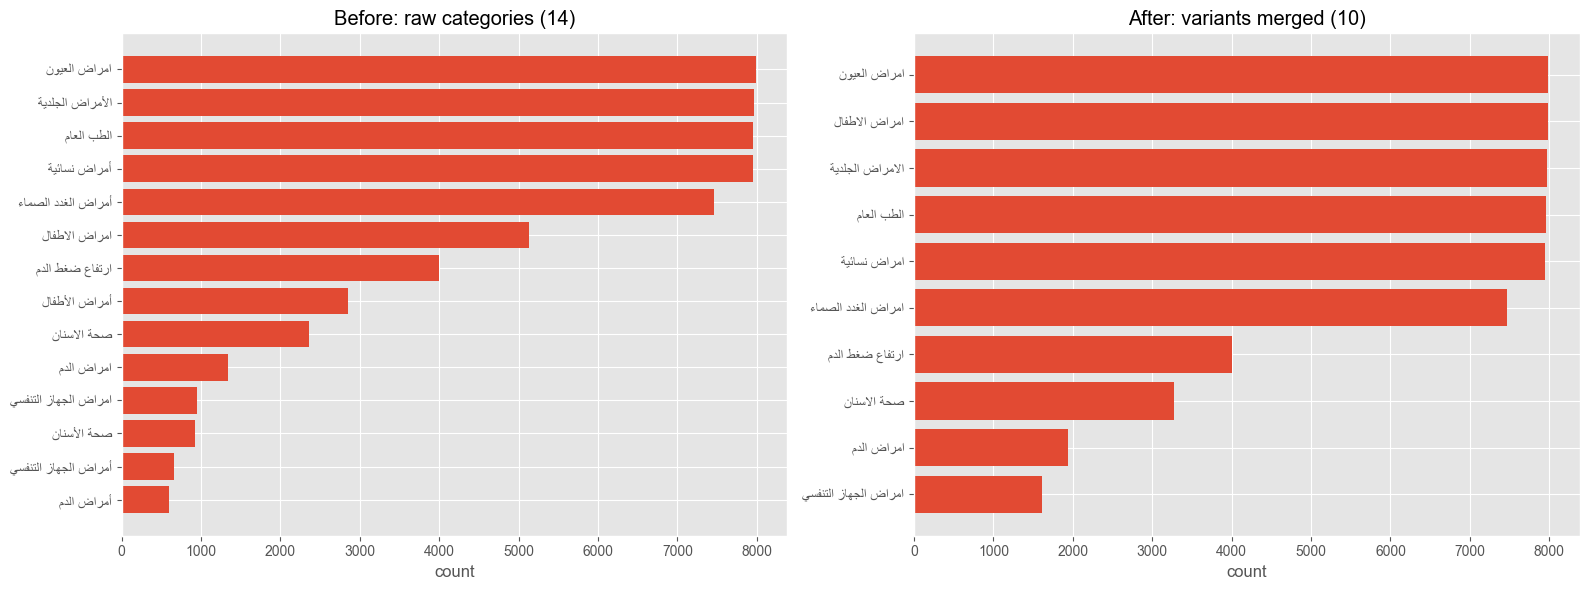

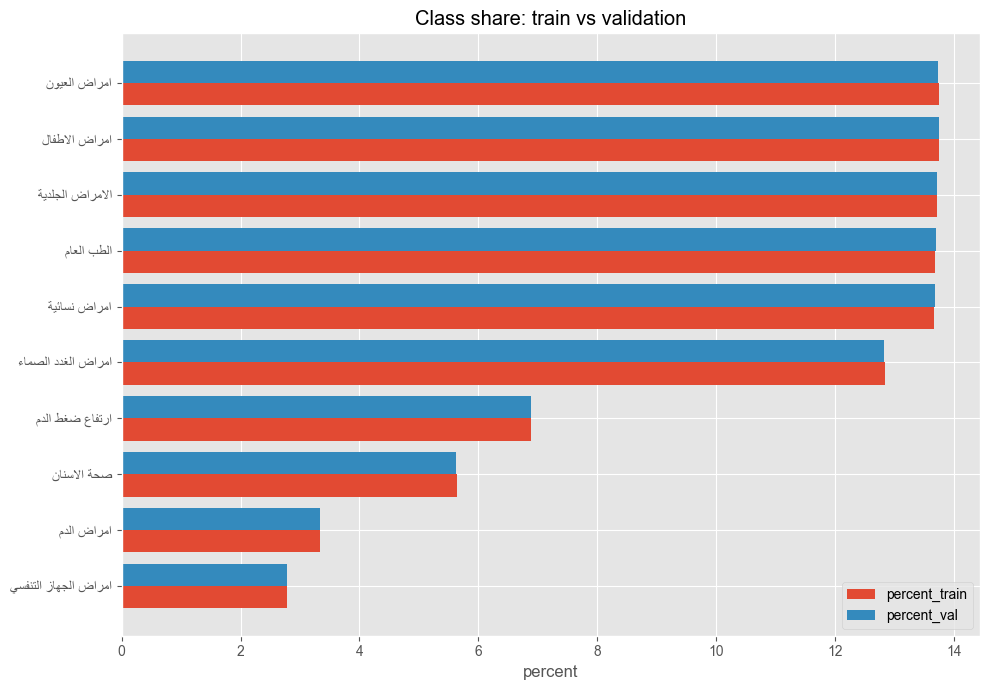

In [11]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
plotter.barh_counts(train[Columns.LABEL].value_counts(), "Before: raw categories (14)", ax=axes[0])
plotter.barh_counts(train[Columns.LABEL].map(ArabicText.normalize).value_counts(), "After: variants merged (10)", ax=axes[1])
plt.tight_layout(); plt.show()

plotter.grouped_barh(merged_dist, ["percent_train", "percent_val"], "Class share: train vs validation")
plt.show()

In [12]:
raw_counts = train[Columns.LABEL].value_counts()
merged_counts = train[Columns.LABEL].map(ArabicText.normalize).value_counts()

print(f"Before merge: {len(raw_counts)} classes, largest/smallest = {ClassDistribution.imbalance_ratio(raw_counts):.1f}, equal share = {ClassDistribution.uniform_share(len(raw_counts))}%")
print(f"After merge : {len(merged_counts)} classes, largest/smallest = {ClassDistribution.imbalance_ratio(merged_counts):.1f}, equal share = {ClassDistribution.uniform_share(len(merged_counts))}%")
print("Largest gap between train and validation class share (percentage points):", merged_dist['abs_diff_pct'].max())

Before merge: 14 classes, largest/smallest = 13.3, equal share = 7.14%
After merge : 10 classes, largest/smallest = 4.9, equal share = 10.0%
Largest gap between train and validation class share (percentage points): 0.01


**✍️ ملاحظتي:**
- الفئات الخام 14 لأن 4 فئات مكتوبة بصيغتين (أطفال، أسنان، دم، جهاز تنفسي) والفرق بس همزة (أمراض/امراض، الأطفال/الاطفال، الأسنان/الاسنان). بعد التوحيد بتصير 10 فئات، وهاد نفس عدد فئات ملف الترميز.
- 17,767 صف (30.6% من train) أسماء فئاتها ما بتطابق ملف الترميز حرفياً (مثلاً `امراض العيون` بالبيانات و`أمراض العيون` بالملف). لو رمّزنا بالمطابقة الحرفية بيطلع NaN لحوالي ثلث البيانات، فلازم نوحّد الأسماء قبل التحويل لأرقام. بعد التوحيد: 0 صف بدون رقم.
- التوازن: الفئات مش متوازنة. 5 فئات حوالي 13.7% كل وحدة (العيون، الأطفال، الجلدية، الطب العام، نسائية) والغدد الصماء 12.8%، وبعدين فئات أصغر: ضغط الدم 6.9% وصحة الأسنان 5.6% وأمراض الدم 3.3% والجهاز التنفسي 2.8%. لو كانت متوازنة تماماً كانت كل فئة 10%. نسبة أكبر فئة لأصغر فئة 4.9 بعد الدمج (كانت 13.3 قبل الدمج، فالرقم الخام كان مضلل لأن الفئة الواحدة منقسمة لصيغتين).
- المعنى للنموذج: الـ accuracy لحاله ممكن يضلل لأن الفئات الكبيرة بتغطي عليه، فنحتاج Macro-F1 و classification_report، ونجرب class_weight (شغل الشخص 3).
- توزيع train و validation شبه متطابق (أكبر فرق 0.01 نقطة مئوية)، وكل الفئات موجودة بالاثنين.

## 4) أطوال الأسئلة

**المشكلة:** النماذج بتتأثر بطول النص، وفي نصوص قصيرة جداً (غير مفيدة) ونصوص طويلة جداً (ممكن تكون ضجيج).
**الطريقة:** عدد الكلمات والأحرف (توزيع عام + لكل فئة) وأقصر وأطول 10 أسئلة.

In [13]:
lengths = LengthProfile()
train_len = lengths.add(train)
lengths.describe(train)

,n_words,n_chars
count,58135.0,58135.0
mean,26.8,140.7
std,13.9,72.8
min,1.0,7.0
5%,7.0,39.0
25%,16.0,86.0
50%,26.0,137.0
75%,34.0,174.0
95%,54.0,290.0
max,168.0,903.0


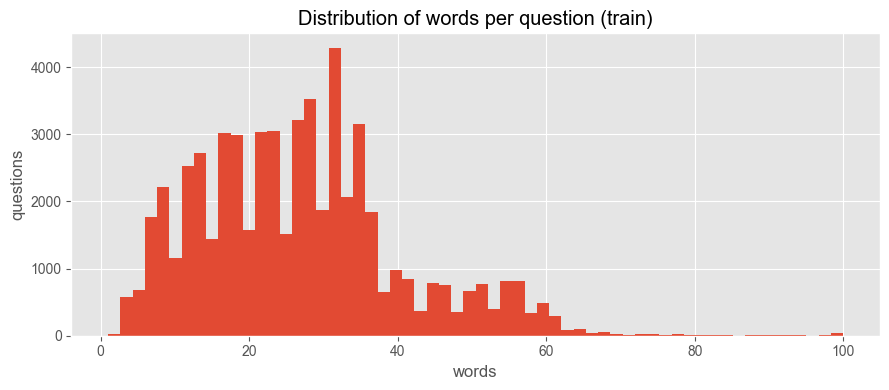

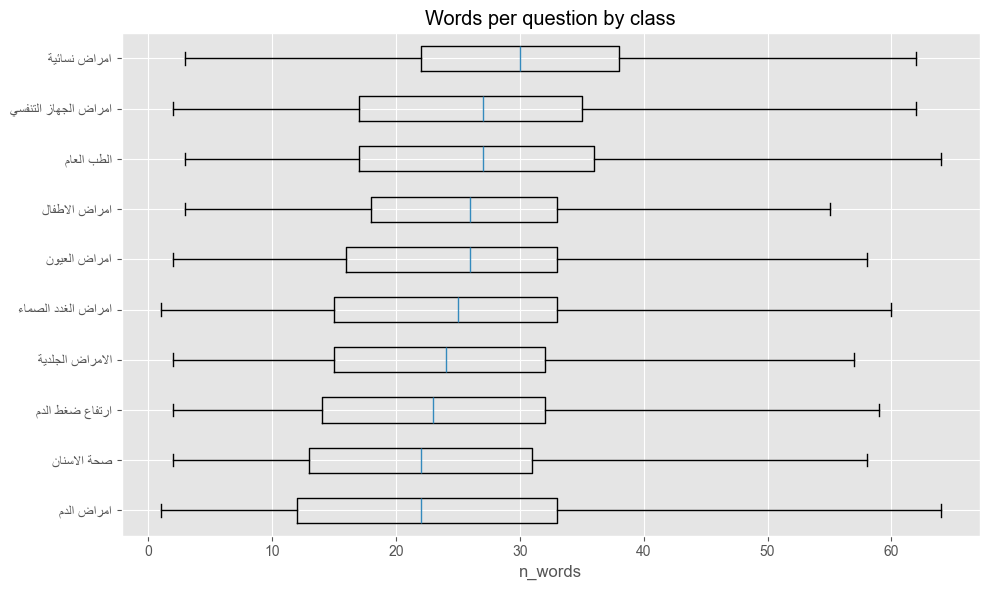

,count,mean,median,min,max
category,,,,,
امراض نسائية,7948,31.5,30.0,3,104
الطب العام,7954,28.2,27.0,3,91
امراض الجهاز التنفسي,1617,28.2,27.0,2,67
امراض الاطفال,7986,26.9,26.0,3,89
امراض العيون,7988,26.3,26.0,2,70
امراض الغدد الصماء,7462,25.8,25.0,1,151
الامراض الجلدية,7971,25.1,24.0,2,138
ارتفاع ضغط الدم,3999,24.5,23.0,2,146
امراض الدم,1933,24.7,22.0,1,119


In [14]:
plotter.histogram(train_len["n_words"], "Distribution of words per question (train)", "words", clip=100)
plt.show()
key = train[Columns.LABEL].map(ArabicText.normalize)
plotter.boxplot_by_class(train_len, "n_words", key, "Words per question by class", clip=100)
plt.show()
lengths.by_class(train, key)

In [15]:
shortest, longest = lengths.extremes(train, 10)
display(shortest)
display(longest[[Columns.ID, "n_words", Columns.LABEL]])
print("Questions with fewer than 4 words:", int((train_len["n_words"] < 4).sum()))
print("Questions with more than 100 words:", int((train_len["n_words"] > 100).sum()))

,id,question,n_words,category
45279,4788,استفسار,1,أمراض الغدد الصماء
28716,4406,hemopilia,1,امراض الدم
30959,2185,هل.حبوب.الدخن.مسموح.سكري.نوع.ثاني,1,امراض الدم
39572,63043,تورم العيون,2,امراض العيون
28387,63970,ثقل العينين,2,امراض العيون
26338,36201,علاج الثعلبة,2,الأمراض الجلدية
45719,68889,ضرس منخور,2,صحة الاسنان
39189,13654,ماهو مرضhashimoto\'s؟,2,أمراض الغدد الصماء
46472,24363,اعراض الظغط,2,ارتفاع ضغط الدم
22956,3374,ماهو برفيريا,2,امراض الدم


,id,n_words,category
18826,71562,168,صحة الأسنان
547,13749,151,أمراض الغدد الصماء
14972,25489,146,ارتفاع ضغط الدم
31628,25685,140,ارتفاع ضغط الدم
10633,33380,138,الأمراض الجلدية
51965,25155,130,ارتفاع ضغط الدم
18130,25763,124,ارتفاع ضغط الدم
9268,25617,122,ارتفاع ضغط الدم
36490,72085,120,صحة الأسنان
7289,12975,119,أمراض الغدد الصماء


Questions with fewer than 4 words: 167
Questions with more than 100 words: 36


**قبل/بعد (طريقة العدّ):** السؤال `هل.حبوب.الدخن.مسموح.سكري.نوع.ثاني` فيه 7 كلمات لكن عدّ المسافات بيعطي كلمة وحدة لأن الكاتب حط نقاط مكان المسافات. يعني عدّ المسافات وحده مش كافي لهيك نصوص.

**✍️ ملاحظتي:**
- عدد الكلمات: المتوسط 26.8 والوسيط 26، و95% من الأسئلة أقل من 54 كلمة. أطول سؤال 168 كلمة (903 حرف). التوزيع مائل لليمين (ذيل طويل: 36 سؤال بأكتر من 100 كلمة).
- الأسئلة القصيرة جداً (أقل من 4 كلمات) عددها 167. معظمها ناقصة أو غير مفيدة مثل `استفسار` و`علاج التسوس`، وبعضها تصنيفه غريب (`الكرياتنين الطبيعي` مصنف أسنان و`البدانية المستعصية` مصنف ضغط)، وهاد مؤشر على ضجيج بالملصقات.
- الطول بيختلف حسب الفئة: وسيط «أمراض نسائية» 30 كلمة و«صحة الأسنان» 22 كلمة، بس الفئات متداخلة كتير بالـ boxplot، فالطول إشارة ضعيفة وما بيحدد الفئة لحاله.

## 5) الكلمات الأكثر تكراراً

**المشكلة:** الكلمات الأكتر تكراراً غالباً كلمات وظيفية أو تحيات، وممكن تغطي على الكلمات الطبية المفيدة.
**الطريقة:** أكتر الكلمات تكراراً بشكل عام ولكل فئة، ومعرفة الكلمات المشتركة بين كل الفئات تقريباً (`WordFrequency`).

In [16]:
words = WordFrequency()                      # after normalization
top = words.top_words(train, 25)
top

,word,count,percent_of_tokens
0,في,36743,2.43
1,من,36657,2.42
2,هل,22585,1.49
3,انا,11188,0.74
4,مع,11067,0.73
5,ان,10485,0.69
6,على,9817,0.65
7,ما,9342,0.62
8,او,9078,0.60
9,بعد,7883,0.52


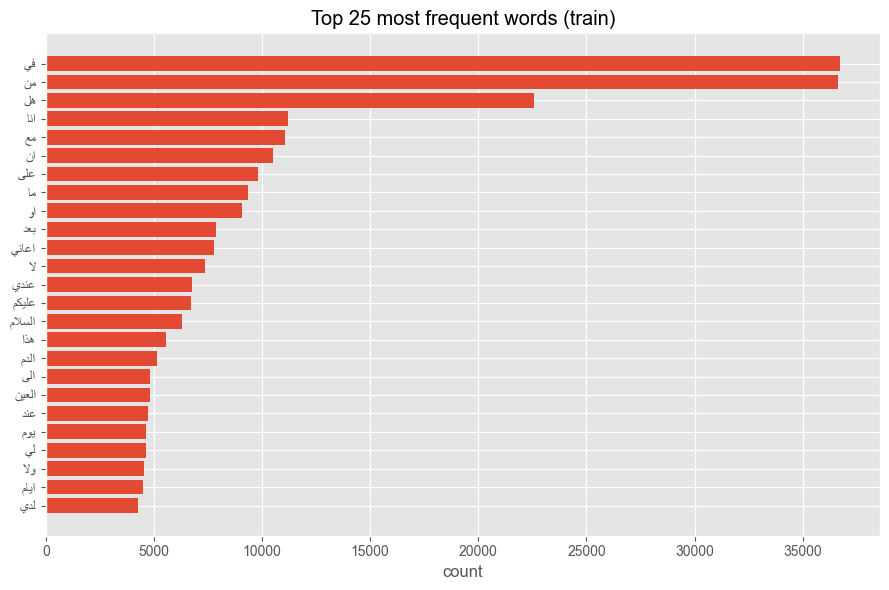

In [17]:
plotter.barh_values(top["word"], top["count"], "Top 25 most frequent words (train)", "count")
plt.show()

In [18]:
words.top_words_by_class(train, key, n=8)

,ارتفاع ضغط الدم,الامراض الجلدية,الطب العام,امراض الاطفال,امراض الجهاز التنفسي,امراض الدم,امراض العيون,امراض الغدد الصماء,امراض نسائية,صحة الاسنان
0,من,في,في,من,في,الدم,في,من,في,من
1,ضغط,من,من,في,من,من,من,في,من,في
2,الدم,هل,هل,هل,التنفس,في,العين,هل,هل,الاسنان
3,الضغط,اعاني,مع,عمره,مع,هل,هل,الغدة,الدورة,هل
4,في,على,انا,عمرها,ضيق,ان,عيني,انا,انا,ان
5,هل,انا,ان,ابني,اعاني,ما,ان,الدرقية,يوم,انا
6,ارتفاع,مع,او,مع,هل,انا,مع,ان,الحمل,عليكم
7,ان,ما,اعاني,سنوات,الصدر,دم,انا,مع,ايام,ما


In [19]:
generic = words.shared_top_words(train, key, n=30, min_classes=8)
print(f"Words in the top 30 of at least 8 classes: {len(generic)}")
generic

Words in the top 30 of at least 8 classes: 16


,word,classes_in_top_n
0,من,10
1,في,10
2,هل,10
3,ان,10
4,على,10
5,ما,10
6,مع,10
7,او,10
8,بعد,10
9,لا,10


**قبل/بعد 2: حجم المفردات قبل وبعد التطبيع**


In [20]:
raw_vocab = WordFrequency(normalize=False).vocabulary_size(train)
norm_vocab = words.vocabulary_size(train)
print(f"Vocabulary size before (split on spaces): {raw_vocab:,}")
print(f"Vocabulary size after (normalization + word splitting): {norm_vocab:,}")
print(f"Reduction: {1 - norm_vocab / raw_vocab:.1%}")
display(WordFrequency(normalize=False).top_words(train, 12))

Vocabulary size before (split on spaces): 126,200
Vocabulary size after (normalization + word splitting): 86,379
Reduction: 31.6%


,word,count,percent_of_tokens
0,في,36608,2.43
1,من,36431,2.42
2,هل,21780,1.44
3,مع,10855,0.72
4,على,9712,0.64
5,ما,9127,0.61
6,انا,8517,0.56
7,بعد,7722,0.51
8,ان,7220,0.48
9,لا,6900,0.46


**✍️ ملاحظتي:**
- أكتر الكلمات ظهوراً كلمات وظيفية: `في` و`من` (2.4% من الكلمات لكل وحدة) ثم `هل` (1.5%). والتحية `السلام عليكم` بتظهر بـ 13.5% من الأسئلة.
- 10 كلمات وظيفية (من، في، هل، ان، على، ما، مع، او، بعد، لا) موجودة بأعلى 30 كلمة عند الفئات العشر كلها، يعني ما بتفرّق بين الفئات. بالمقابل أكتر كلمات كل فئة بتعكس تخصصها (ضغط/الدم للضغط، الدورة/الحمل للنسائية، العين/عيني للعيون، الأسنان للأسنان، التنفس/الصدر للجهاز التنفسي، الغدة/الدرقية للغدد الصماء).
- انتباه: `لا` و`ما` كلمات شائعة بس بتحمل معنى النفي («لا أعاني من…» غير «أعاني من…»)، فحذف الـ stop words بدون مراجعة ممكن يضر.
- التطبيع قلّل حجم المفردات من 126,200 إلى 86,379 (حوالي 31.6%)، لأن صيغ الهمزة وعلامات الترقيم اللاصقة كانت تتعدّ كلمات مختلفة. التطبيع هون للتحليل فقط، والتنظيف الفعلي بـ `preprocess.py` عند الشخص 2.

## 6) الأنماط النصية (regex)

**المشكلة:** نصوص المرضى مكتوبة بحرية: أرقام، أحرف لاتينية، تشكيل، تطويل، تحيات، عامية…
**الطريقة:** نعدّ كم سؤال فيه كل نمط (`PatternCounter`) مع مثال.

In [21]:
patterns = PatternCounter()
pattern_table = patterns.count(train)
pattern_table

,rows,percent,example
pattern,,,
Arabic-Indic digits (٠-٩),8905,15.32,العمر ٤٢ سنة مريض ضغط باخد بيزوكارد10 اشعر بإرهاق عام دائما فذهبت لعمل تحليل سكر تراكمي ف
Western digits (0-9),17086,29.39,العمر ٤٢ سنة مريض ضغط باخد بيزوكارد10 اشعر بإرهاق عام دائما فذهبت لعمل تحليل سكر تراكمي ف
Latin letters,6330,10.89,انا فتاه غير متزوجة عمري 34 سنه وزني 75 سنه وطولي 160 اعاني من مشكلة الحديد . حيث دائما ار
Emoji,16,0.03,هل شرب كوب شاي واحد في اليوم يؤثر على الهيموجلوبين ارجوو الرد على سؤالي وشكرررراً ❤️
URL,7,0.01,السلام عليكم \r\nانا شاب عمري 17 عاما واعاني من مشكلة خروج الدم من الفرج كما الموضحة بالصورة
Diacritics (tashkeel),4458,7.67,منذ حوالي خمسة أشهر، لاحظت نزول دم مع البراز لمدة أسبوع تقريبًا، ولم يكن مصحوبًا بأي ألم.
Tatweel (ـ),189,0.33,أنآ سويت عملية استئصال الغدة قبل سنه ونص لاحظت مـن وقتها للحين اعاني ببحة في صوتي مرات بسي
Repeated letters (3+),3303,5.68,انا فتاه غير متزوجة عمري 34 سنه وزني 75 سنه وطولي 160 اعاني من مشكلة الحديد . حيث دائما ار
Greeting,7822,13.45,السلام عليكم هل خمول الغدة والدوالي يؤثران على نسبة الحديد ومخزونه في الدم؟ وشكرا


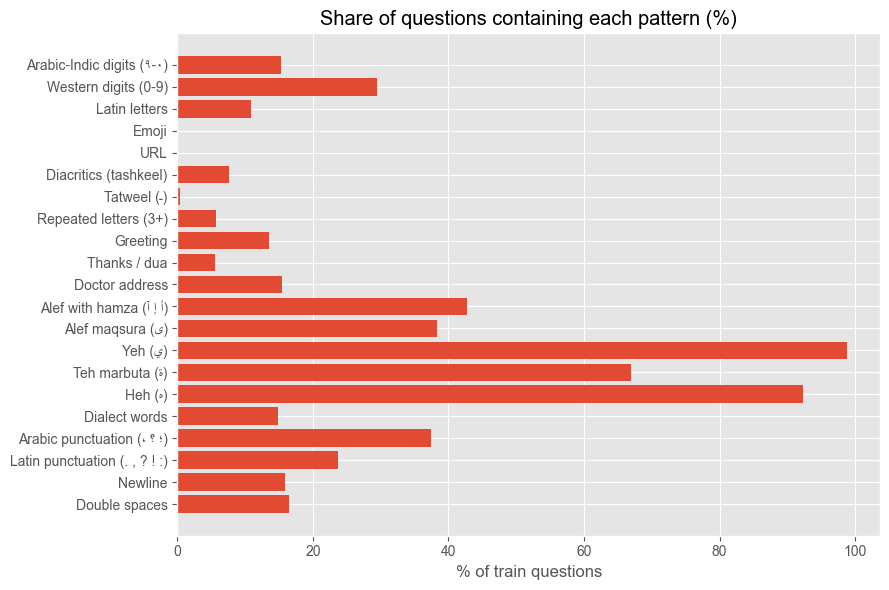

In [22]:
plotter.barh_values(pattern_table.index, pattern_table["percent"], "Share of questions containing each pattern (%)", "% of train questions")
plt.show()

**قبل/بعد 3: الأسئلة اللي فيها همزة على الألف قبل وبعد التوحيد**


In [23]:
text = train[Columns.TEXT]
with_hamza = text.str.contains("[أإآ]").mean()
normalized = text.map(ArabicText.normalize)
print(f"Questions with a hamza on alef before unification: {with_hamza:.1%}")
print(f"After unification: {normalized.str.contains('[أإآ]').mean():.1%}")
print(f"Vocabulary size before/after: {WordFrequency(normalize=False).vocabulary_size(train):,} -> {words.vocabulary_size(train):,}")

Questions with a hamza on alef before unification: 42.7%
After unification: 0.0%
Vocabulary size before/after: 126,200 -> 86,379


**✍️ ملاحظتي:**
- **الأرقام:** 29.4% من الأسئلة فيها أرقام غربية (0-9) و15.3% أرقام هندية (٠-٩)، يعني بصيغتين ومحتاجين نوحّدهم (نتائج تحاليل مثل `6.4` أو `٦.٣`).
- **حروف لاتينية:** 10.9% (أسماء أدوية وتحاليل مثل TSH وB12). معلومات طبية، فحذفها ضرر.
- **أشكال الحروف:** 42.7% من الأسئلة فيها همزة على الألف (بعد التوحيد 0%)، و38.3% فيها `ى`، و67% فيها `ة`. الكتابة غير موحدة، فتوحيد الألف مهم، أما `ى/ي` و`ة/ه` فقرار تجريبي.
- **تشكيل** 7.7% و**تطويل** 0.3% و**حروف مكررة** 5.7%: نسب قليلة وحذفها آمن.
- **ترقيم:** علامات عربية (، ؛ ؟) بـ 37.4% وإنجليزية (. , ? ! :) بـ 23.7%، فلازم المعالجة تشمل النوعين.
- **تنسيق:** أسطر جديدة 15.8% ومسافات مزدوجة 16.5%، وبتتصلّح بتنظيف خفيف.
- **عبارات اجتماعية:** تحيات 13.5%، مخاطبة الدكتور 15.4%، شكر/دعاء 5.5%، متكررة وما فيها معلومة طبية.
- **عامية** 14.9% (حسب قائمة كلمات صغيرة، فالنسبة الحقيقية على الأرجح أعلى).
- روابط وإيموجي نادرة (7 و16 صف) فتأثيرها ضعيف.

## 7) التكرار والتشابه

**المشكلة:** الأسئلة المكررة أو المتشابهة جداً بتخلي النموذج يحفظ بدل ما يتعلم، وبتنفخ نتيجة التقييم لو وصلت لـ validation.
**الطريقة:** (أ) تكرار مطابق بالنص الخام وبعد التطبيع، داخل كل ملف؛ (ب) تضارب الفئات بين النسخ المكررة؛ (ج) تشابه جزئي بـ TF-IDF + NearestNeighbors على دفعات (الـ vectorizer يتعلم على train فقط).

In [24]:
finder = DuplicateFinder()
rows = []
for name, df in splits.items():
    rows.append({"split": name,
                 "rows in dup groups (raw)": len(finder.within(df, normalized=False)),
                 "rows in dup groups (normalized)": len(finder.within(df, normalized=True))})
pd.DataFrame(rows).set_index("split")

,rows in dup groups (raw),rows in dup groups (normalized)
split,,
train,50,58
val,0,0
test,0,0


In [25]:
dups = finder.within(train, normalized=True)
dups[[Columns.ID, Columns.TEXT, Columns.LABEL]].head(12)

,id,question,category
27540,49370,ابني عمرو ٤ شهور والو يومين زي اللي فيه بلغم بزورو وبقحقح منو وفيه مخاط بأنفو ومطلع صوت زي الشخير كيف يمكن اني اعالجه,امراض الاطفال
40167,49363,ابني عمرو ٤ شهور والو يومين زي اللي فيه بلغم بزورو وبقحقح منو وفيه مخاط بأنفو ومطلع صوت زي الشخير كيف يمكن اني اعالجه,امراض الاطفال
55214,50790,ابني يعاني من انسداد الانف مع سيلان مع سعال قوي مصحوب ببلغم تصل الى ترجيع الطعام,امراض الاطفال
41012,50791,ابني يعاني من انسداد الانف مع سيلان مع سعال قوي مصحوب ببلغم تصل الى ترجيع الطعام,امراض الاطفال
2065,393,أعالج عند طبيب الأمراض الصدرية عن حساسية القصبات الهوائية فوصف لي دواء ايزوبتيل اربع قطرات قبل النوم مع العلم اني لا...,أمراض الجهاز التنفسي
35808,394,أعالج عند طبيب الأمراض الصدرية عن حساسية القصبات الهوائية فوصف لي دواء ايزوبتيل اربع قطرات قبل النوم مع العلم اني لا...,أمراض الجهاز التنفسي
57903,31504,اعاني من تساقط الشعر مع العلم اني استخدم زيوت ومرطبات افيدوني,الأمراض الجلدية
16903,31503,اعاني من تساقط الشعر مع العلم اني استخدم زيوت ومرطبات افيدوني,الأمراض الجلدية
3385,38977,أعاني من صداع شديداشبه بالضغط على الرأس من الجانبين بعد القيام من وضعية الانبطاح ؟\r\nاستمريت فتره على فيتامين دال و...,الطب العام
16287,38975,أعاني من صداع شديداشبه بالضغط على الرأس من الجانبين بعد القيام من وضعية الانبطاح ؟\r\nاستمريت فتره على فيتامين دال و...,الطب العام


**تضارب الفئات:** نفس السؤال بفئتين مختلفتين

In [26]:
conflicts = finder.label_conflicts(train)
print("Conflicting rows:", len(conflicts))
conflicts[[Columns.ID, Columns.TEXT, Columns.LABEL]]

Conflicting rows: 8


,id,question,category
23360,5537,السلام عليكم ورحمة الله\r\nعملت فحص للسكر صائم لاكثر من شهرين ونص وكلها لاتزيد على 90 وبعد الاكل بساعتين 125-145 وبع...,أمراض الغدد الصماء
13498,41166,السلام عليكم ورحمة الله\r\nعملت فحص للسكر صائم لاكثر من شهرين ونص وكلها لاتزيد على 90 وبعد الاكل بساعتين 125-145 وبع...,الطب العام
42719,2362,انا عملت تحليل انيميا وطلعت نسبه mchc 30 النسبه كدا مظبوطه ولا محتاج علاج لو محتاج علاج ايه العلاج المطلوب,امراض الدم
37115,41344,انا عملت تحليل انيميا وطلعت نسبه mchc 30 النسبه كدا مظبوطه ولا محتاج علاج لو محتاج علاج ايه العلاج المطلوب,الطب العام
21053,22043,انا عندي ارتفاع في الضغط استخدم دواء amlocard ولكن عند قياسه ارى ان هناك اختلف كبير في القرات تكون القراى الاولة 180...,ارتفاع ضغط الدم
17242,5633,انا عندي ارتفاع في الضغط استخدم دواء amlocard ولكن عند قياسه ارى ان هناك اختلف كبير في القرات تكون القراى الاولة 180...,أمراض الغدد الصماء
37910,32344,عندي بردودة وتعرق في اليدين ولما عملت تحاليل قلولي عندك فرط في نشاط الغدة الدرقية\r\n\r\n\r\nكيف بقدر أقلل من نشاطها...,الأمراض الجلدية
47703,7245,عندي بردودة وتعرق في اليدين ولما عملت تحاليل قلولي عندك فرط في نشاط الغدة الدرقية\r\n\r\nكيف بقدر أقلل من نشاطها الز...,أمراض الغدد الصماء


**التشابه الجزئي** (cosine على TF-IDF؛ نقارن كل سؤال بأقرب سؤال بـ train):

In [27]:
sim = SimilarityFinder(train)                       # fit on train only
nearest_train_self = sim.nearest_within_reference()   # train against itself
nearest_val = sim.nearest_in_reference(val)
nearest_test = sim.nearest_in_reference(test)

summary = pd.concat({
    "train (vs train)": SimilarityFinder.threshold_table(nearest_train_self["similarity"]),
    "validation (vs train)": SimilarityFinder.threshold_table(nearest_val["similarity"]),
    "test (vs train)": SimilarityFinder.threshold_table(nearest_test["similarity"]),
}, axis=1)
summary

train (vs train)         validation (vs train)         test (vs train)        
                          rows percent                  rows percent            rows percent
similarity >=                                                                               
0.99                        74    0.13                    10    0.14               7    0.10
0.95                        84    0.14                    16    0.22              10    0.14
0.90                       128    0.22                    22    0.30              14    0.19
0.80                       254    0.44                    40    0.55              38    0.52
0.70                       473    0.81                    73    1.00              64    0.88

In [28]:
near_dups = nearest_train_self[nearest_train_self["similarity"] >= 0.90]
same = (near_dups["label"].map(ArabicText.normalize) == near_dups["neighbour_label"].map(ArabicText.normalize))
print(f"Near-duplicate pairs >= 0.90 inside train: {len(near_dups)}, same category: {same.mean():.1%}")
near_dups.sort_values("similarity", ascending=False)[["id", "neighbour_id", "similarity", "label", "neighbour_label", "text"]].head(8)

Near-duplicate pairs >= 0.90 inside train: 128, same category: 85.9%


,id,neighbour_id,similarity,label,neighbour_label,text
36,59476,59480,1.0,امراض العيون,امراض العيون,انا ذهبت الى الطبيب و اجريت فحص لعيني و لكني لا اعاني من اعراض طارئة مثل دوخة و وجع في الرأس او العين فقط ضعف الرؤية...
205,71621,71620,1.0,صحة الاسنان,صحة الاسنان,هل تزول حساسية الاسنان نهائيا؟ واذا كان كذلك ماهي الطرق المتبعة؟ شكراً
277,42403,42402,1.0,الطب العام,الطب العام,مرحبا اود الاستفسار عن هذه الفحوصات هل جميعها من تحاليل الدم ام لا ؟ وهل اخذ هذه الادوية تؤثر في نتيجتها ام لا \r\n١...
2065,393,394,1.0,أمراض الجهاز التنفسي,أمراض الجهاز التنفسي,أعالج عند طبيب الأمراض الصدرية عن حساسية القصبات الهوائية فوصف لي دواء ايزوبتيل اربع قطرات قبل النوم مع العلم اني لا...
5967,5291,5292,1.0,أمراض الغدد الصماء,أمراض الغدد الصماء,هل كسل الغده الدرقيه يسبب السمنه\n \n\nماهي الماده الفعاله التي تستخدم في الادويه المنشطه للغده الدرقيه
4024,52427,52426,1.0,أمراض الأطفال,أمراض الأطفال,طفلي عمره سنتين وشهرين يعاني من الاسهال اصبح يرفض الاكل وصفت له الدكتورة دواء فلازول له 3 ايام يشرب الدواء لا اجد اي...
3385,38977,38975,1.0,الطب العام,الطب العام,أعاني من صداع شديداشبه بالضغط على الرأس من الجانبين بعد القيام من وضعية الانبطاح ؟\r\nاستمريت فتره على فيتامين دال و...
6392,27306,27307,1.0,الأمراض الجلدية,الأمراض الجلدية,أعاني من مرض التهاب الجلد الدهني المزمن ما هي افضل علاجات لالتهاب الجلد الدهني لفروة الرأس و الوجه التي لا تحتوي على...


**قبل/بعد 4: أثر التطبيع على كشف التكرار** (الجدول فوق: التكرار الحرفي مقابل التكرار بعد التطبيع).

**✍️ ملاحظتي:**
- داخل train في 50 صف ضمن مجموعات مكررة حرفياً، وبعد التطبيع بتصير 58. داخل validation و test ما في ولا تكرار.
- أغلب التكرارات أسئلة منشورة مرتين بـ id قريبة جداً من بعض (مثل 393 و394، و31503 و31504)، يعني غالباً نفس السؤال اتجمع مرتين.
- **تضارب الفئات:** 8 صفوف (4 أسئلة) نفس النص فيها بفئات مختلفة (مثلاً سؤال سكر مصنف «غدد صماء» ومرة «الطب العام»). هاد ضجيج بالملصقات، وبيدل إن حدود الفئات مش حادة خصوصاً مع «الطب العام».
- **التشابه الجزئي:** أزواج التشابه >= 0.90 داخل train عددها 128 (0.22%)، و85.9% منها بنفس الفئة. النسبة صغيرة فتأثيرها محدود، بس مهم نعرفها لأنها بتوصل ل validation و test 

## 8) التسريب (leakage) بين train / validation / test

**المشكلة:** لو سؤال موجود بـ train وبـ validation، نتيجة التقييم بتطلع أحسن من الحقيقة (النموذج حافظه).
**الطريقة:** نعدّ الأسئلة المشتركة بين كل زوج من الملفات، حرفياً وبعد التطبيع (`LeakageDetector`)، وبعدين نشوف التسريب شبه المطابق من القسم السابق.

In [29]:
leak = LeakageDetector(train, val, test)
leak.exact_report()

,rows_checked,exact_raw,exact_normalized,percent_normalized
pair,,,,
validation in train,7267,6,9,0.12
test in train,7267,3,5,0.07
test in validation,7267,0,0,0.00


In [30]:
leaked_val = leak.val_rows_matching_train()
print("Validation rows that also appear in train:", len(leaked_val))
print("Same category:", int(leaked_val["same_label"].sum()), "| different category:", int((~leaked_val["same_label"]).sum()))
leaked_val[[Columns.ID, Columns.TEXT, Columns.LABEL, "train_labels", "same_label"]]

Validation rows that also appear in train: 9
Same category: 5 | different category: 4


,id,question,category,train_labels,same_label
351,3938,ماهى نسبة التحليل التى تفيد ان فيرس سى نشط فى الكبد\r\n5.3,امراض الدم,{امراض الدم},True
864,5849,انا عمري ١٧ سنه وطولي ١٦٨ سنتيمتر وانا اقصر من اخوتي بقد من ٥ الي ٧ سنتيمتر وذهبت لطبيب غدد صماء واخبرني ان مادام حد...,أمراض الغدد الصماء,{الطب العام},False
1347,2373,السلام عليكم ورحمة الله وبركاته \r\nممكن الرد على سؤالي و هو هل نسبة الهيموجلوبين ١٠.٨ يعتبر نسبة طبيعية لمرأة عمره...,امراض الدم,{الطب العام},False
2590,384,عانى أخي من التهاب رئوي جراء إصابته في كورونا السنة الماضية\nو هو مصاب بها الآن فكيف نتصرف؟هل يجب إعطائه الكورتيزون ...,امراض الجهاز التنفسي,{الطب العام},False
3087,5011,تحليل سكر تراكمي قبل ٣ شهور ٦.٣ وكان وزني وقتها ١١٧ واليوم نتيجه التحليل ٥.٣ ونزل من وزني ٢٠ ك هل يعني ذلك تجاوزي م...,أمراض الغدد الصماء,{امراض الغدد الصماء},True
3448,42016,هل يجوز اخذ حقنة B12 بالوريد عيار 500 ؟؟؟\r\nوهل انتفاخ الكاحلان بالقدم بعد اخد الحقن الوريدة هو السبب ؟؟ وهل يجب مر...,الطب العام,{الطب العام},True
6059,5762,السلام عليكم انا لما كن عمري ١٩ و انا اتعلج من مرض قصور الغدة الدرقية بأخد الدواء leyvotirox50 الان tsh عندي معتدل ا...,أمراض الغدد الصماء,{امراض الغدد الصماء},True
6180,43320,نسبة الانسولين صائم 13.2 وتحليل السكر صائم 95 هل هذه القيم طبيعية ؟؟وكيف احتسب مقاومة الانسولين من هذه النتائج؟ هل ا...,الطب العام,{امراض الغدد الصماء},False
6190,42614,بعض الأيام بنهاية يوم العمل فجأة اشعر بالجوع ورعشة وانهيار بالجسم رغم ان اخر تحاليل السكر التراكمي وصائم طبيعية وصور...,الطب العام,{الطب العام},True


In [31]:
leaked_test = leak.test_rows_matching_train()
print("Test rows that also appear in train:", len(leaked_test))
leaked_test[[Columns.ID, Columns.TEXT]]

Test rows that also appear in train: 5


,id,question
1158,50487,إبني 8 شهور ولم يبدأ التسنين جبتله هاي كال لكن رفضه.وهل صحيح لو مشي مش هيسنن غير متاخر
2660,1656,السلام عليكم اريدعلاج للربو مجرب و مضمون علما بأنني اعاني من ضيق في التنفس اثناء الذهاب الي النوم و كذلك في ساعة الص...
3582,40550,فحصت الدهون الشامل بعد صيام 10 ساعات تقريباً وسكر الصائم ونتيجه الكوليسترول الكلي 217 في الفحص الاول والسكر ٩٦ ام فح...
4161,46000,لا اعاني من اي اعراض
6373,67002,انا حامل في الاسبوع ٢٢ وصف لي طبيبي منذ الاسبوع السادس دواء Prednisone 5 mg حبتين يومياً حتى آخر الحمل بسبب إجهاض سا...


In [32]:
near_val = nearest_val[nearest_val["similarity"] >= 0.90]
near_test = nearest_test[nearest_test["similarity"] >= 0.90]
print(f"Similarity >= 0.90 with train -> validation: {len(near_val)} ({len(near_val)/len(val):.2%}) | test: {len(near_test)} ({len(near_test)/len(test):.2%})")
agree = (near_val["query_label"].map(ArabicText.normalize) == near_val["match_label"].map(ArabicText.normalize))
print(f"Of the similar validation questions, share with the same category as the nearest train neighbour: {agree.mean():.1%}")

Similarity >= 0.90 with train -> validation: 22 (0.30%) | test: 14 (0.19%)
Of the similar validation questions, share with the same category as the nearest train neighbour: 72.7%


**قبل/بعد 5: validation قبل وبعد حذف الصفوف المسرّبة من train**


In [33]:
val_clean = leak.val_without_leakage()
print(f"validation before: {len(val):,} rows -> after removing rows leaked from train: {len(val_clean):,} rows (removed {len(val) - len(val_clean)})")
print(f"test: {len(test):,} rows before and after (no test row is ever removed)")

validation before: 7,267 rows -> after removing rows leaked from train: 7,258 rows (removed 9)
test: 7,267 rows before and after (no test row is ever removed)


**✍️ ملاحظتي (القرار):**
- التسريب صغير: 9 أسئلة من validation (0.12%) موجودة حرفياً بعد التطبيع بـ train (6 بس بالفحص الحرفي)، و5 أسئلة من test موجودة بـ train، و0 بين test و validation.
- من الـ 9 المسرّبة، 4 فئتها بـ validation **مختلفة** عن فئتها بـ train (مثلاً غدد صماء مقابل الطب العام)، يعني حتى لو حفظ النموذج السؤال ما بيضمن الجواب الصح. دليل إضافي على ضجيج الملصقات.
- **القرار:** نحذف الـ 9 صفوف المسرّبة من **validation فقط** (7,267 → 7,258) حتى يكون تقييم قدرة النموذج على التعميم عادل. ما بنحذف شي من **test** (لازم التسليم يحتوي كل الـ ids)، وحذف التكرار من **train** قرار الشخص 2.
- التسريب شبه المطابق (>= 0.90): 22 صف بـ validation (0.30%) و14 بـ test (0.19%). من أسئلة validation المتشابهة، 72.7% بنفس فئة أقرب جار بـ train. نتركها لأن الأسئلة المتشابهة مش بالضرورة مكررة وعددها قليل.